# Laboratorium 3 — Dane obrazowe i wideo: potok i własny zbiór

**Cel:** zbudować potok danych od plików do tensorów. Wczytamy własny mini-zbiór przez `ImageFolder`, podejrzymy augmentację, a następnie potraktujemy **wideo jako sekwencję klatek** i przepuścimy klatki przez ten sam potok co obrazy.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 0. Instalacja zależności

In [1]:
#!pip install torch torchvision opencv-python-headless matplotlib

## Import bibliotek i wybór urządzenia

In [13]:
import os, urllib.request
import numpy as np
import cv2
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import csv
import shutil
from collections import Counter


torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| OpenCV:", cv2.__version__, "| urządzenie:", device)

PyTorch: 2.9.1 | OpenCV: 5.0.0 | urządzenie: cpu


## 1. Zbuduj własny mini-zbiór (dwie klasy)

W realnym zadaniu podkładasz **własne zdjęcia** w układzie `dane/<klasa>/*.jpg`. Aby notatnik był samowystarczalny, wygenerujemy prosty zbiór dwóch klas figur: **kolo** i **kwadrat**.

In [3]:
ROOT = "dane_demo"
classes_demo = ["kolo", "kwadrat"]
N_PER_CLASS = 60

def make_image(kind, size=64):
    bg = tuple(int(x) for x in np.random.randint(20, 80, size=3))
    img = Image.new("RGB", (size, size), bg)
    d = ImageDraw.Draw(img)
    color = tuple(int(x) for x in np.random.randint(120, 255, size=3))
    m = np.random.randint(6, 14)
    box = [m, m, size-m, size-m]
    if kind == "kolo":
        d.ellipse(box, fill=color)
    else:
        d.rectangle(box, fill=color)
    return img

for c in classes_demo:
    os.makedirs(f"{ROOT}/{c}", exist_ok=True)
    for i in range(N_PER_CLASS):
        make_image(c).save(f"{ROOT}/{c}/{c}_{i:03d}.jpg")
print("Utworzono zbiór:", ROOT)
for c in classes_demo:
    print(f"  {c}: {len(os.listdir(ROOT+'/'+c))} obrazów")

Utworzono zbiór: dane_demo
  kolo: 60 obrazów
  kwadrat: 60 obrazów


## 2. Wczytaj zbiór przez ImageFolder

`ImageFolder` sam wykrywa klasy z nazw podkatalogów i przypisuje im indeksy. Podłączamy transformacje i `DataLoader`.

Klasy: ['kolo', 'kwadrat'] -> indeksy: {'kolo': 0, 'kwadrat': 1}
Liczba przykładów: 120
Paczka: (16, 3, 64, 64) | etykiety: [1, 0, 1, 1, 0, 1, 0, 0]


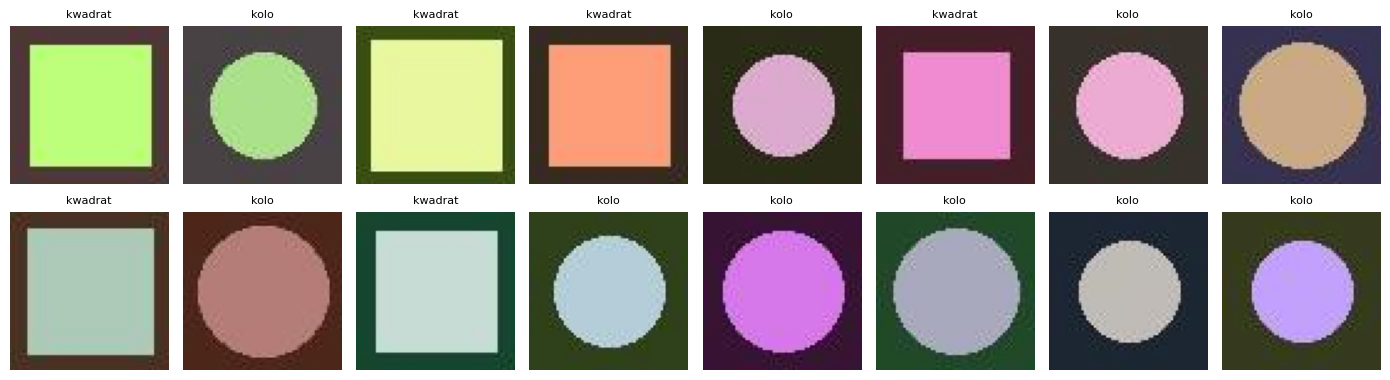

In [4]:
eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
train_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

ds = datasets.ImageFolder(ROOT, transform=eval_tf)
print("Klasy:", ds.classes, "-> indeksy:", ds.class_to_idx)
print("Liczba przykładów:", len(ds))
dl = DataLoader(ds, batch_size=16, shuffle=True)

xb, yb = next(iter(dl))
print("Paczka:", tuple(xb.shape), "| etykiety:", yb[:8].tolist())
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow((img*0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title(ds.classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Podgląd augmentacji

Ta sama augmentacja zastosowana wielokrotnie do jednego obrazu daje różne warianty — to zwiększa różnorodność zbioru treningowego.

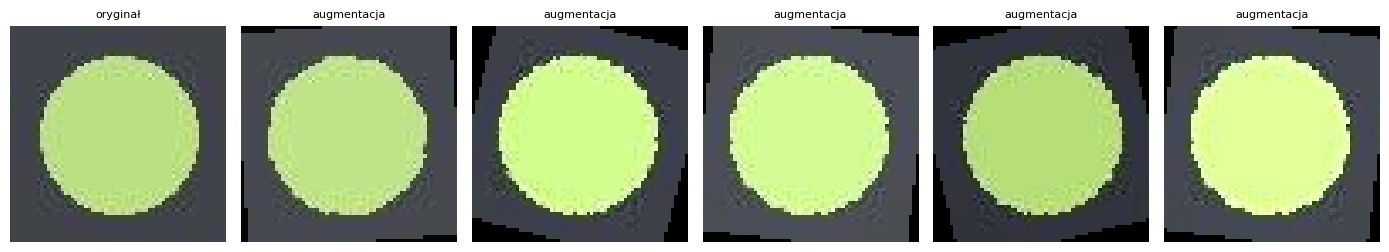

In [5]:
raw = Image.open(ds.samples[0][0]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(raw); axes[0].set_title("oryginał", fontsize=8); axes[0].axis("off")
for ax in axes[1:]:
    aug = train_tf(raw)
    ax.imshow((aug*0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title("augmentacja", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Wideo jako sekwencja klatek

W realnym zadaniu wczytujesz **własny plik wideo**. Tu wygenerujemy krótki film (poruszające się koło), a potem odczytamy go klatka po klatce. Uwaga: OpenCV zwraca klatki w kolejności **BGR** — konwertujemy na RGB.

Zapisano film: demo.avi
FPS: 20.0 | liczba klatek: 60 | pobrano co 10. -> 6 klatek


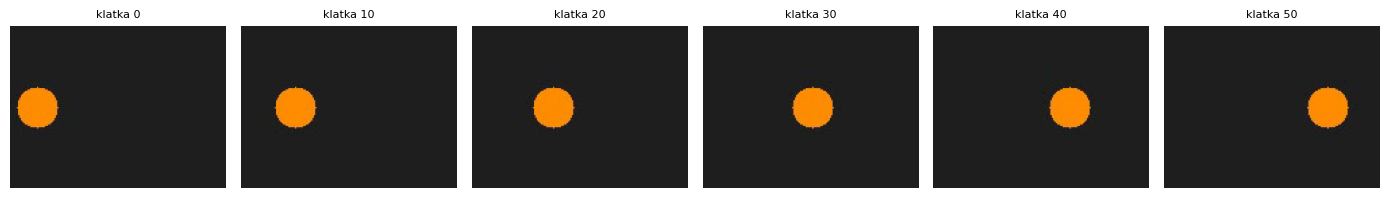

In [6]:
VIDEO = "demo.avi"
H, W, FPS, N_FRAMES = 120, 160, 20, 60
vw = cv2.VideoWriter(VIDEO, cv2.VideoWriter_fourcc(*"MJPG"), FPS, (W, H))
for t in range(N_FRAMES):
    frame = np.full((H, W, 3), 30, np.uint8)
    cx = int(20 + (W-40)*t/(N_FRAMES-1))
    cv2.circle(frame, (cx, H//2), 15, (0, 140, 255), -1)  # kolor w BGR
    vw.write(frame)
vw.release()
print("Zapisano film:", VIDEO)

def sample_frames(path, every=10):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames, i = [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i % every == 0:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))  # BGR -> RGB
        i += 1
    cap.release()
    return frames, fps, total

frames, fps, total = sample_frames(VIDEO, every=10)
print(f"FPS: {fps} | liczba klatek: {total} | pobrano co 10. -> {len(frames)} klatek")
fig, axes = plt.subplots(1, len(frames), figsize=(14, 2.6))
for ax, fr, idx in zip(axes, frames, range(len(frames))):
    ax.imshow(fr); ax.set_title(f"klatka {idx*10}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Klatki → tensory → gotowy model

Klatka wideo to zwykły obraz, więc przechodzi przez ten sam potok co zdjęcie. Poniżej pobieramy krótki **prawdziwy** film (w Colab), próbkujemy klatki, stosujemy preprocessing gotowego modelu i klasyfikujemy każdą klatkę.

Uwaga: klasyfikator ImageNet rozpoznaje 1000 kategorii obiektów (nie ma osobnej klasy „osoba") — istotny jest tu **potok** (klatka → tensor → model), a nie trafność etykiet. Realną detekcję obiektów na wideo poznamy na zajęciach 12.

Pobrano przykładowy film.
Paczka klatek: (6, 3, 224, 224)


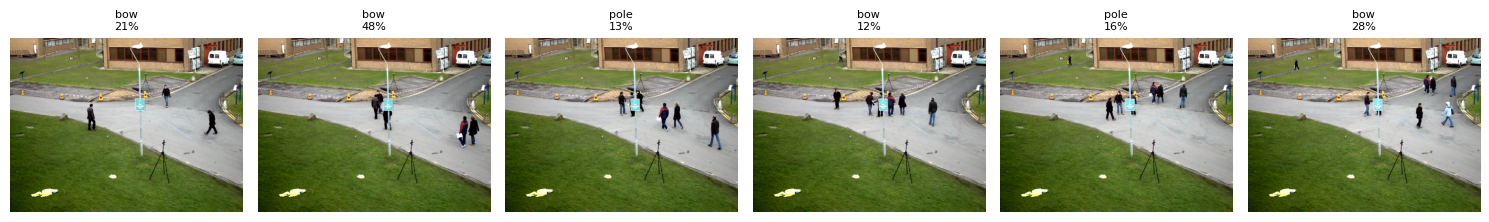

In [7]:
from torchvision.models import resnet18, ResNet18_Weights

video_path = "sample_video.avi"
try:
    urllib.request.urlretrieve(
        "https://github.com/opencv/opencv/raw/refs/heads/5.x/samples/data/vtest.avi", video_path)
    print("Pobrano przykładowy film.")
except Exception as e:
    video_path = VIDEO  # fallback: film syntetyczny z sekcji 4
    print("Nie udało się pobrać filmu, używam syntetycznego:", e)

frames, fps, total = sample_frames(video_path, every=25)
frames = frames[:6]

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()
preprocess = weights.transforms()
categories = weights.meta["categories"]

batch = torch.stack([preprocess(Image.fromarray(fr)) for fr in frames]).to(device)  # [T,3,H,W]
print("Paczka klatek:", tuple(batch.shape))
with torch.no_grad():
    probs = model(batch).softmax(1)
top = probs.argmax(1)

fig, axes = plt.subplots(1, len(frames), figsize=(15, 3))
for ax, fr, i in zip(axes, frames, range(len(frames))):
    ax.imshow(fr)
    ax.set_title(f"{categories[top[i]]}\n{probs[i, top[i]].item()*100:.0f}%", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Źródła danych i RODO

- Używaj danych, do których masz prawa.
- **Wizerunek twarzy to dane osobowe** (RODO) — wymaga podstawy prawnej/zgody; przy publikacji rozważ anonimizację (rozmycie twarzy, tablic rejestracyjnych).
- Ostrożnie z nagraniami w przestrzeni publicznej — szczególnie w zastosowaniach typu monitoring czy liczenie osób.

## 7. Podsumowanie

- `Dataset` daje pojedynczy przykład, `DataLoader` robi paczki, tasowanie i wczytywanie równoległe.
- `ImageFolder` = najprostszy własny zbiór (podkatalog = klasa).
- Wideo to sekwencja klatek; każda klatka to obraz `[C, H, W]`, próbkujemy co N-tą.
- OpenCV zwraca **BGR** — pamiętaj o konwersji na RGB.
- Klatki i zdjęcia przechodzą przez ten sam potok transforms.

**Zadanie na sprawozdanie:** zobacz `zadanie.md`.

---
*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

In [11]:
shutil.rmtree("dane", ignore_errors=True)

# film -> (klasa, split, co która klatka)
VIDEOS = {
    "cat1.mp4": ("kot",  "train", 4),
    "cat2.mp4": ("kot",  "val",   5),
    "dog1.mp4": ("pies", "train", 6),
    "dog2.mp4": ("pies", "val",   5),
}
ROOT = "dane"

log_rows = []
for vid, (cls, split, every) in VIDEOS.items():
    cap = cv2.VideoCapture(vid)
    if not cap.isOpened():
        print("NIE OTWORZYŁO:", vid); continue
    fps = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    out_dir = f"{ROOT}/{split}/{cls}"
    os.makedirs(out_dir, exist_ok=True)
    i, saved = 0, 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        if i % every == 0:
            name = f"{os.path.splitext(vid)[0]}_f{i:05d}.jpg"
            cv2.imwrite(f"{out_dir}/{name}", frame)
            log_rows.append([vid, cls, split, i, round(i/fps, 2), name])
            saved += 1
        i += 1
    cap.release()
    print(f"{vid}: FPS={fps:.2f}, klatek (metadane)={total}, przeczytano={i}, "
          f"zapisano={saved}, co {every}. klatka, odstęp={every/fps:.2f} s")

with open("klatki_log.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["film", "klasa", "split", "indeks_klatki", "czas_s", "plik"])
    w.writerows(log_rows)

for split in ["train", "val"]:
    for c in ["kot", "pies"]:
        print(split, c, len(os.listdir(f"{ROOT}/{split}/{c}")))

cat1.mp4: FPS=23.98, klatek (metadane)=145, przeczytano=145, zapisano=37, co 4. klatka, odstęp=0.17 s
cat2.mp4: FPS=25.00, klatek (metadane)=253, przeczytano=253, zapisano=51, co 5. klatka, odstęp=0.20 s
dog1.mp4: FPS=30.00, klatek (metadane)=222, przeczytano=222, zapisano=37, co 6. klatka, odstęp=0.20 s
dog2.mp4: FPS=24.00, klatek (metadane)=233, przeczytano=233, zapisano=47, co 5. klatka, odstęp=0.21 s
train kot 37
train pies 37
val kot 51
val pies 47


In [14]:
SIZE = 64

eval_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
train_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

train_ds = datasets.ImageFolder("dane/train", transform=train_tf)
val_ds   = datasets.ImageFolder("dane/val",   transform=eval_tf)
assert train_ds.class_to_idx == val_ds.class_to_idx, "mapowanie klas się różni!"

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl   = DataLoader(val_ds,   batch_size=16, shuffle=False)

for name, d in [("train", train_ds), ("val", val_ds)]:
    cnt = Counter(d.targets)
    print(f"{name}: klas={len(d.classes)}, razem={len(d)}")
    for c, idx in d.class_to_idx.items():
        print(f"  {c} (idx {idx}): {cnt[idx]} obrazów")
print("class_to_idx:", train_ds.class_to_idx)

xb, yb = next(iter(train_dl))
print("Paczka:", tuple(xb.shape), "| etykiety:", yb.tolist())

train: klas=2, razem=74
  kot (idx 0): 37 obrazów
  pies (idx 1): 37 obrazów
val: klas=2, razem=98
  kot (idx 0): 51 obrazów
  pies (idx 1): 47 obrazów
class_to_idx: {'kot': 0, 'pies': 1}
Paczka: (16, 3, 64, 64) | etykiety: [1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0]


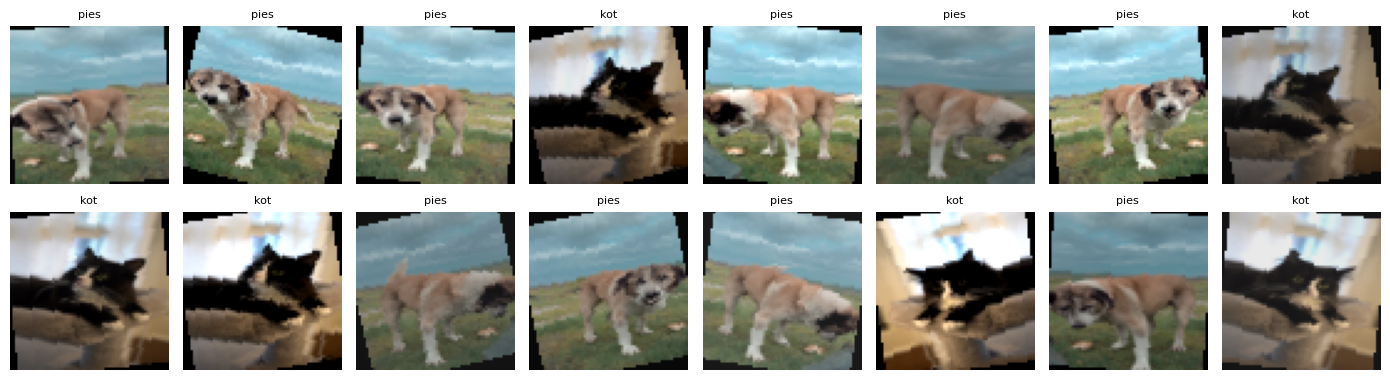

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow((img*0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy())b
    ax.set_title(train_ds.classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

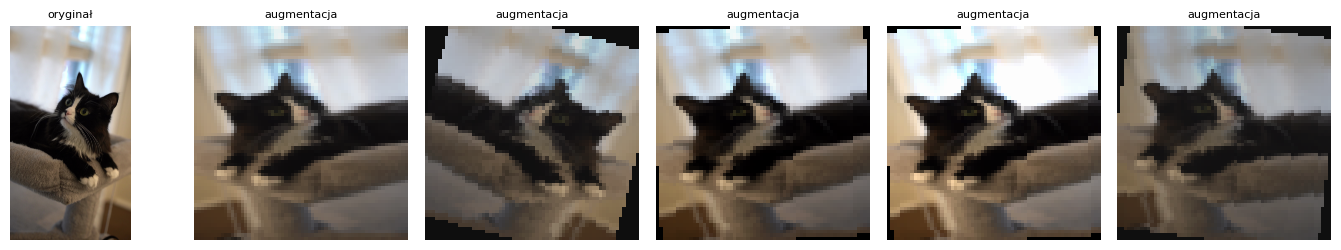

In [16]:
raw = Image.open(train_ds.samples[0][0]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(raw); axes[0].set_title("oryginał", fontsize=8); axes[0].axis("off")
for ax in axes[1:]:
    aug = train_tf(raw)
    ax.imshow((aug*0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title("augmentacja", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()